# Synthetic baseline v2: SMARTS-like differential rotation

Companion to `README.md`. Regenerates every figure from `data/` (copy of `runs/synth200_s0_v2/`). Scoring: `success` = `correct` (within 10% of P_eq) + `diffrot` (within 10% of the active-latitude-band period range).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-13_synthetic-baseline-v2-diffrot"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


In [2]:
sys.path.insert(0, str(REPO / 'benchmarks'))
import scorecard
from IPython.display import Image, display
per_star = pd.read_csv(DATA / 'per_star.csv')
per_method = pd.read_csv(DATA / 'per_method.csv')
metrics = json.loads((DATA / 'metrics.json').read_text())
BINS = list(ev.PERIOD_BIN_LABELS)
per_star['band_ratio'] = per_star.period_hi / per_star.period_lo
per_star['success'] = per_star.final_outcome.isin(ev.SUCCESS_OUTCOMES)
print(len(per_star), 'stars;', metrics['config']['dataset'], 'scorecard v', metrics['config']['scorecard_version'])

200 stars; synthetic:n=200,seed=0 scorecard v 2


## Figures 1–3: standard scorecard figures

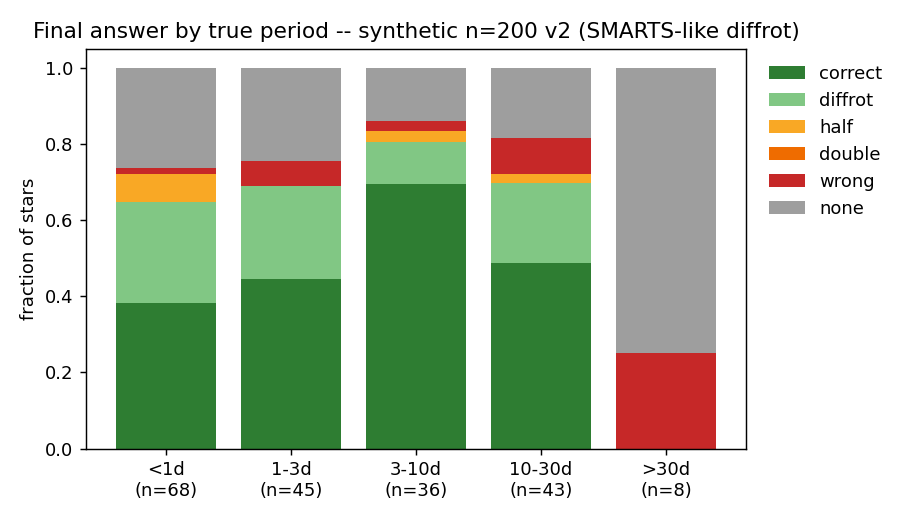

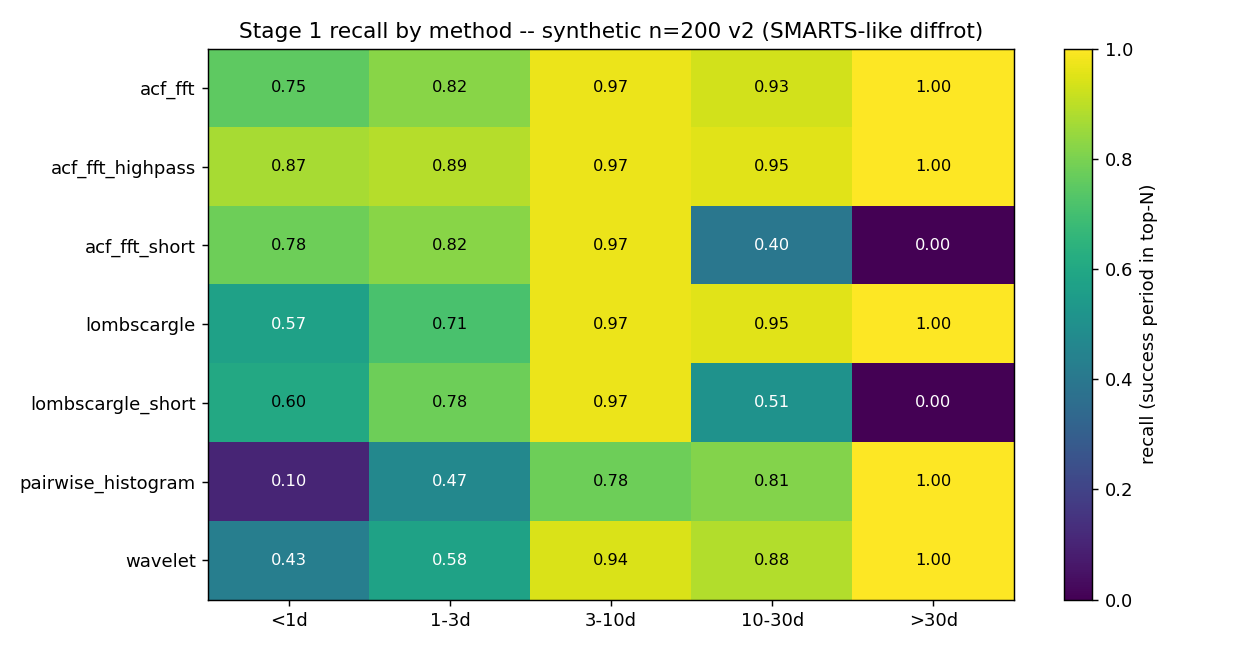

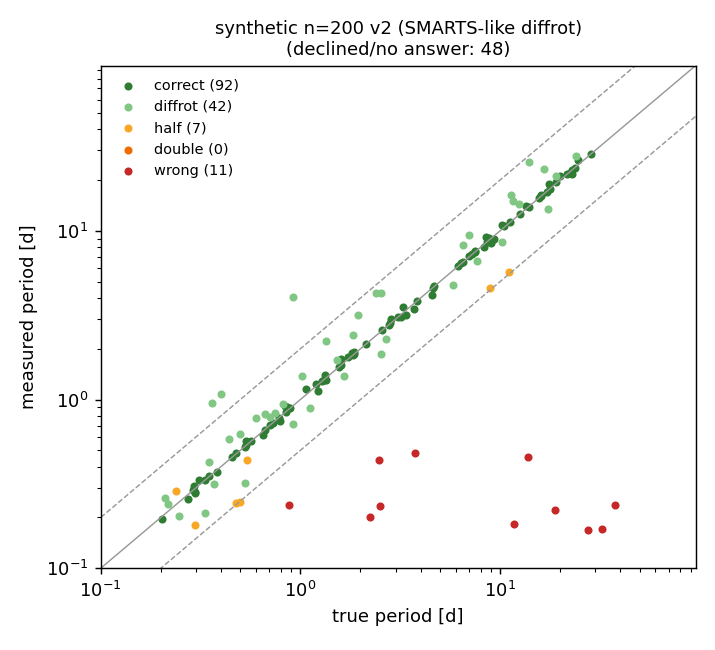

In [3]:
scorecard.make_figures(per_star, per_method, FIG, 'synthetic n=200 v2 (SMARTS-like diffrot)')
for f in ['fig_final_outcomes_by_bin.png', 'fig_method_recall_by_bin.png', 'fig_measured_vs_true.png']:
    display(Image(FIG / f))

## Figure 4: how much the scoring change matters
The same run scored two ways: P_eq only (old rule: `correct`) and P_eq or the active band (`success`). Right: how wide the band is. 52% of stars have a band reaching beyond ±10% of P_eq.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
g = per_star.groupby('period_bin')
tab = pd.DataFrame({'P_eq only (correct)': g.final_outcome.apply(lambda x: np.mean(x == ev.CORRECT)),
                    'success (correct + diffrot)': g.success.mean()}).reindex(BINS)
tab.plot.bar(ax=axes[0], rot=0, color=['#2e7d32', '#81c784']); axes[0].set_ylim(0, 1); axes[0].set_ylabel('fraction of stars')
axes[0].set_title('Final answer: old vs new success criterion'); axes[0].legend(frameon=False)
axes[1].hist(np.log10(per_star.band_ratio.clip(upper=100)), bins=40, color='0.4')
axes[1].axvline(np.log10(1.1 / 0.9), color='r', ls='--', label='band wider than the ±10% P_eq window')
axes[1].set_xlabel('log10(P_hi / P_lo) of active latitude band'); axes[1].set_ylabel('stars'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'fig_scoring_change.png', dpi=130); plt.show()
display(tab.round(2))

/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_39836/710321700.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(FIG / 'fig_scoring_change.png', dpi=130); plt.show()


,P_eq only (correct),success (correct + diffrot)
period_bin,,
<1d,0.38,0.65
1-3d,0.44,0.69
3-10d,0.69,0.81
10-30d,0.49,0.70
>30d,0.00,0.00


## Figure 5: where the pipeline declines
Decline and success rates vs inclination, shear and SNR.

In [5]:
bins = {'meta_inclination_deg': ([0, 20, 40, 60, 90], 'inclination [deg]'),
        'meta_shear': ([-1.01, -0.1, -1e-9, 1e-9, 0.3, 1.01], 'shear (>0 solar-like)'),
        'meta_snr': ([0, 2, 5, 20], 'SNR (amplitude / white noise)')}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, (edges, lab)) in zip(axes, bins.items()):
    b = pd.cut(per_star[col], edges)
    t = per_star.assign(declined=per_star.final_outcome == ev.NONE).groupby(b, observed=True)[['declined', 'success']].mean()
    n = per_star.groupby(b, observed=True).size()
    t.index = [f'{iv}\n(n={n[iv]})' for iv in t.index]
    t.plot.bar(ax=ax, rot=0, color=['#9e9e9e', '#2e7d32']); ax.set_ylim(0, 1); ax.set_xlabel(lab); ax.legend(frameon=False)
    ax.tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.savefig(FIG / 'fig_declines.png', dpi=130); plt.show()

/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_39836/3360527982.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(FIG / 'fig_declines.png', dpi=130); plt.show()


## Figure 6: what diffrot answers look like
Measured / P_eq for `diffrot` outcomes against the star's shear. Solar-like shear (>0) gives longer measured periods, anti-solar gives shorter, as the butterpy convention predicts.

In [6]:
d = per_star[per_star.final_outcome == ev.DIFFROT]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d.meta_shear, d.final_period / d.true_period, s=18, color='#81c784', edgecolor='k', lw=0.3)
ax.axhline(1, color='0.5', lw=0.8); ax.axhspan(0.9, 1.1, color='0.9', label='correct window')
ax.set_xlabel('shear'); ax.set_ylabel('measured / P_eq'); ax.set_title(f'diffrot outcomes (n={len(d)})'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'fig_diffrot_vs_shear.png', dpi=130); plt.show()

/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_39836/2199358484.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(FIG / 'fig_diffrot_vs_shear.png', dpi=130); plt.show()
